In the [forward-propagation note](../forward-propagation/index.qmd), a layer is $\mathbf{a} = W f(\mathbf{a}_{\text{prev}}) + \mathbf{b}$, and **row $j$ of $W$ holds all the weights into node $j$**. Here I want to know whether those numbers *mean* anything:

- If a network classifies points, do its weights describe the **decision boundary**?
- If a network recognizes shapes, do its weights look like **basic shapes**?

## Two ways to read one row of $W$

For a first-layer node with input $\mathbf{x}$, weight row $\mathbf{w}_j$, and bias $b_j$:

$$
a_j = \mathbf{w}_j \cdot \mathbf{x} + b_j .
$$

The same formula can be pictured in two ways.

**1. As a boundary (low-dimensional input).** The set where $a_j = 0$ is a line in 2D — a hyperplane in general. The node is "off" on one side and "on" on the other; $\mathbf{w}_j$ points across the line toward the "on" side, and the line sits at distance $\lvert b_j\rvert/\lVert\mathbf{w}_j\rVert$ from the origin. The **length** $\lVert\mathbf{w}_j\rVert$ sets how sharp the switch is: a tanh node goes from $-0.76$ to $+0.76$ as $a_j$ goes from $-1$ to $1$, which is a band of width $2/\lVert\mathbf{w}_j\rVert$ around the line. Long weight vectors give sharp, step-like switches; short ones give gradual ramps.

**2. As a template (high-dimensional input, like an image).** Write the dot product as

$$
\mathbf{w}_j \cdot \mathbf{x} = \lVert\mathbf{w}_j\rVert\,\lVert\mathbf{x}\rVert\cos\theta .
$$

Among all inputs of a given length, the one that drives node $j$ hardest is the one pointing the same way as $\mathbf{w}_j$ ($\theta = 0$). So if the input is an image, **reshaping $\mathbf{w}_j$ back into an image shows the pattern the node looks for**. Positive weights reward ink in those pixels, negative weights penalize it.

**The output layer** then combines the hidden nodes: its weight $v_{k,j}$ says how strongly node $j$ votes for (or against) class $k$.

## The study

- **Part 1 — boundaries.** Points in 2D, two classes, one hidden layer of tanh nodes. I draw every hidden node's line and band on top of the learned decision boundary.
- **Part 2 — shapes.** Small $12\times12$ images built from known **stroke primitives**, so I can check whether the weights recover them. I compare a classifier with no hidden layer, one with a hidden layer, a task designed to *reward* learning the primitives, a constraint (non-negative weights), and the effect of moving the shapes around.

All networks are trained the same way: softmax output, cross-entropy loss, full-batch Adam. Backpropagation stays a black box for now, as in the [architecture study](../architecture-study/index.ipynb).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations

plt.rcParams["figure.dpi"] = 110
NODE_COLORS = plt.cm.tab10.colors

## The network and training (black box)

Layer sizes are `[n_in, hidden..., n_classes]`, with an element-wise activation in the hidden layers and **softmax** at the output. Training minimizes the cross-entropy loss plus a small **weight decay** $\tfrac{\lambda}{2}\sum \lVert W\rVert^2$, which keeps weights from growing without bound and makes weight images less noisy. One option, `nonneg=True`, forces the first-layer weights to stay $\ge 0$ (used in section 2C).

In [2]:
ACT = {   # name -> (f, f', init gain)
    "tanh": (np.tanh,                     lambda z: 1 - np.tanh(z) ** 2,   1.0),
    "relu": (lambda z: np.maximum(0, z),  lambda z: (z > 0).astype(float), 2.0),
}

def init_params(sizes, act, seed, sigma_b=0.1):
    rng = np.random.default_rng(seed)
    params = []
    for l, (n_in, n_out) in enumerate(zip(sizes[:-1], sizes[1:])):
        g = ACT[act][2] if l < len(sizes) - 2 else 1.0
        params.append([np.sqrt(g / n_in) * rng.standard_normal((n_out, n_in)),
                       sigma_b * rng.standard_normal(n_out)])
    return params

def softmax(A):
    E = np.exp(A - A.max(1, keepdims=True))
    return E / E.sum(1, keepdims=True)

def forward(params, X, act):
    """Rows of X are samples: a = H W^T + b; hidden h = f(a); output = softmax(a).
    Returns class probabilities and the cache [(a, h), ...]."""
    f = ACT[act][0]
    h = X
    cache = [(None, h)]
    for l, (W, b) in enumerate(params):
        a = h @ W.T + b
        h = f(a) if l < len(params) - 1 else a
        cache.append((a, h))
    return softmax(h), cache

def loss_and_grads(params, X, y, act, wd):
    df = ACT[act][1]
    prob, cache = forward(params, X, act)
    N = len(X)
    loss = -np.mean(np.log(prob[np.arange(N), y] + 1e-12)) + 0.5 * wd * sum((W**2).sum() for W, _ in params)
    Y = np.zeros_like(prob); Y[np.arange(N), y] = 1
    delta = (prob - Y) / N                                   # dL/da at the softmax output
    grads = [None] * len(params)
    for l in reversed(range(len(params))):
        W, _ = params[l]
        grads[l] = [delta.T @ cache[l][1] + wd * W, delta.sum(0)]
        if l > 0:
            delta = (delta @ W) * df(cache[l][0])
    return loss, grads

def train(params, X, y, act, steps=2000, lr=0.01, wd=0.0, nonneg=False):
    params = [[W.copy(), b.copy()] for W, b in params]
    if nonneg:
        params[0][0] = np.abs(params[0][0])
    m = [[np.zeros_like(p) for p in layer] for layer in params]
    v = [[np.zeros_like(p) for p in layer] for layer in params]
    for t in range(1, steps + 1):
        _, g = loss_and_grads(params, X, y, act, wd)
        for l in range(len(params)):
            for k in range(2):
                m[l][k] = 0.9 * m[l][k] + 0.1 * g[l][k]
                v[l][k] = 0.999 * v[l][k] + 0.001 * g[l][k] ** 2
                params[l][k] -= lr * (m[l][k] / (1 - 0.9**t)) / (np.sqrt(v[l][k] / (1 - 0.999**t)) + 1e-8)
        if nonneg:
            params[0][0] = np.maximum(params[0][0], 0.0)      # project back onto W >= 0
    return params

def accuracy(params, X, y, act):
    return float((forward(params, X, act)[0].argmax(1) == y).mean())

# Gradient check (central differences on random entries).
rng = np.random.default_rng(0)
Xc, yc = rng.standard_normal((15, 5)), rng.integers(0, 3, 15)
for act in ACT:
    p = init_params([5, 4, 3], act, 1); _, g = loss_and_grads(p, Xc, yc, act, 0.01); worst = 0
    for l in range(2):
        for k in range(2):
            A = p[l][k]; i = np.unravel_index(rng.integers(A.size), A.shape); old = A[i]
            A[i] = old + 1e-6; lp, _ = loss_and_grads(p, Xc, yc, act, 0.01)
            A[i] = old - 1e-6; lm, _ = loss_and_grads(p, Xc, yc, act, 0.01); A[i] = old
            num = (lp - lm) / 2e-6
            worst = max(worst, abs(num - g[l][k][i]) / (abs(num) + abs(g[l][k][i]) + 1e-12))
    print(f"{act}: max relative gradient error {worst:.1e}")

tanh: max relative gradient error 1.5e-09
relu: max relative gradient error 2.2e-09


# Part 1 — Hidden nodes as boundary pieces (2D input)

**Setup.** 600 points uniform in $[-3, 3]^2$, labeled by whether they fall inside a region. The network is $2 \to H \to 2$ with tanh hidden nodes, trained for 3000 steps (learning rate 0.02, no weight decay).

**How each plot reads.**

- Background: the predicted probability of the inside class (red); the thick black curve is the decision boundary (probability $0.5$).
- Each hidden node $j$ is one colored **solid line** $a_j = 0$, with **dashed lines** at $a_j = \pm1$ marking its transition band (width $2/\lVert\mathbf{w}_j\rVert$).
- The **arrow** is $\mathbf{w}_j$'s direction.

With two output classes, only the *difference* of the two output rows matters (softmax is shift-invariant), so node $j$'s **vote** is $v_j = W^{(2)}_{\text{in},j} - W^{(2)}_{\text{out},j}$. Also, flipping the signs of $\mathbf{w}_j$, $b_j$, and $v_j$ together gives the *same* network, because tanh is odd. So for display I flip each node so that $v_j > 0$. Then **every arrow points toward the side where that node adds evidence for "inside"**.

In [3]:
LO, HI = -3, 3
rng = np.random.default_rng(0)
X2 = rng.uniform(LO, HI, (600, 2))

TRI = np.array([[-2.0, -1.5], [2.0, -1.5], [0.0, 2.2]])
def inside_triangle(X):
    s = [(b[0] - a[0]) * (X[:, 1] - a[1]) - (b[1] - a[1]) * (X[:, 0] - a[0])
         for a, b in zip(TRI, np.roll(TRI, -1, axis=0))]
    s = np.array(s)
    return ((s > 0).all(0) | (s < 0).all(0)).astype(int)

y_tri = inside_triangle(X2)
y_disk = (np.hypot(X2[:, 0], X2[:, 1]) < 1.8).astype(int)

g = np.linspace(LO, HI, 300)
GX, GY = np.meshgrid(g, g)
GRID = np.column_stack([GX.ravel(), GY.ravel()])

def canonical_nodes(params):
    """First-layer (w_j, b_j) and votes v_j, sign-flipped so that every v_j > 0."""
    W, b = params[0][0].copy(), params[0][1].copy()
    v = params[1][0][1] - params[1][0][0]
    s = np.where(v < 0, -1.0, 1.0)
    return W * s[:, None], b * s, v * s

def draw_line(ax, w, c, **kw):
    """Draw {x : w.x + c = 0} across the plotting window."""
    n = np.linalg.norm(w)
    p0 = -c * w / n**2                       # point on the line closest to the origin
    d = np.array([-w[1], w[0]]) / n          # direction along the line
    t = np.array([-20.0, 20.0])
    ax.plot(p0[0] + t * d[0], p0[1] + t * d[1], **kw)
    return p0

def plot_nodes(ax, params, X, y, title, bands=True):
    prob = forward(params, GRID, "tanh")[0][:, 1].reshape(GX.shape)
    ax.contourf(GX, GY, prob, levels=np.linspace(0, 1, 21), cmap="RdBu_r", alpha=0.35)
    ax.contour(GX, GY, prob, levels=[0.5], colors="k", linewidths=2.4)
    ax.scatter(X[:, 0], X[:, 1], c=np.where(y == 1, "#b2182b", "#2166ac"), s=6, alpha=0.6)
    W, b, v = canonical_nodes(params)
    for j in range(len(b)):
        col = NODE_COLORS[j]
        p0 = draw_line(ax, W[j], b[j], color=col, lw=2.0)
        if bands:
            draw_line(ax, W[j], b[j] - 1, color=col, lw=1.0, ls="--")
            draw_line(ax, W[j], b[j] + 1, color=col, lw=1.0, ls="--")
        p0 = np.clip(p0, LO + 0.4, HI - 0.4)
        u = W[j] / np.linalg.norm(W[j])
        ax.annotate("", xy=p0 + 0.7 * u, xytext=p0,
                    arrowprops=dict(arrowstyle="-|>", color=col, lw=2, mutation_scale=14))
        ax.plot([], [], color=col, lw=2, label=fr"node {j+1}: $\|w\|$={np.linalg.norm(W[j]):.1f}, vote {v[j]:.1f}")
    ax.set_xlim(LO, HI); ax.set_ylim(LO, HI); ax.set_aspect("equal")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=7, loc="lower left", framealpha=0.85)

## 1A. A triangle with exactly 3 hidden nodes

A triangle is the intersection of three half-planes, so 3 nodes are *just enough* — if each node takes one side. Four random starts:

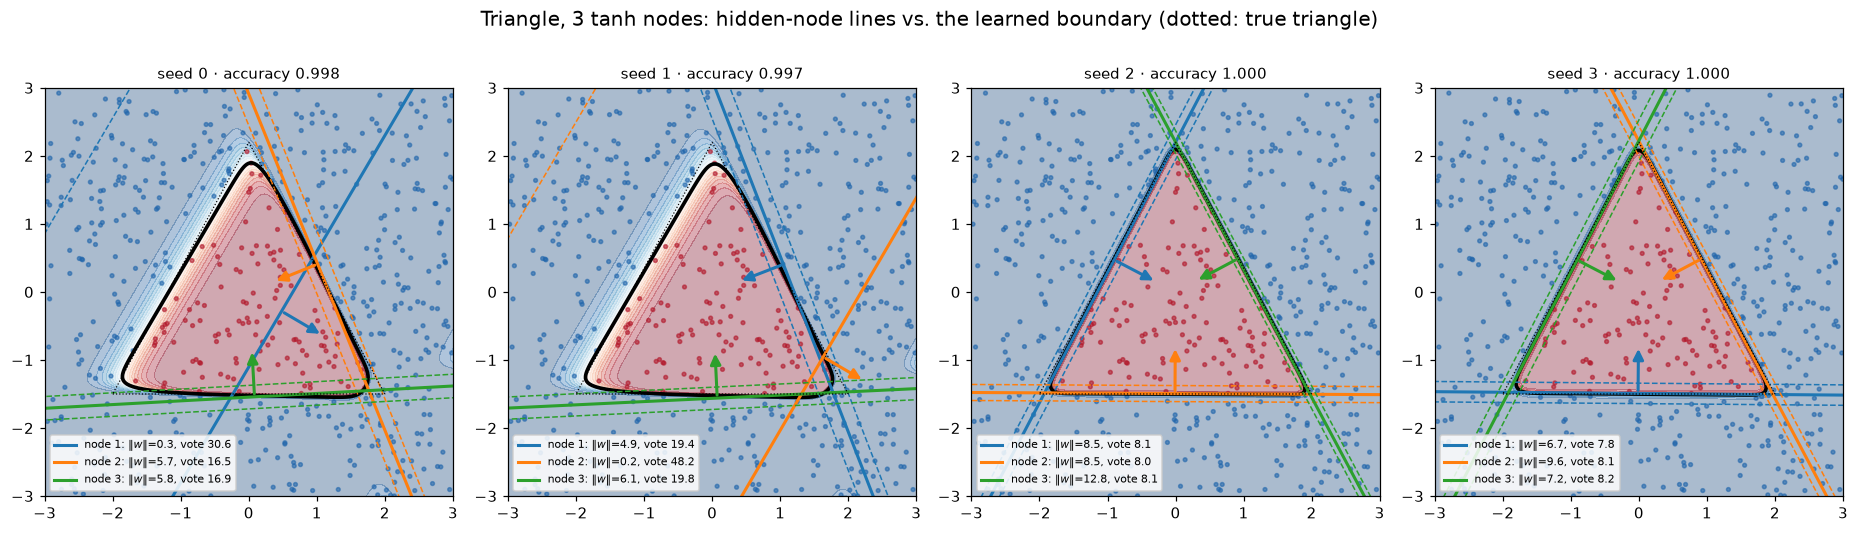

In [4]:
TRI_SEEDS = [0, 1, 2, 3]
tri_nets = {s: train(init_params([2, 3, 2], "tanh", s), X2, y_tri, "tanh", steps=3000, lr=0.02)
            for s in TRI_SEEDS}

fig, axes = plt.subplots(1, 4, figsize=(17, 4.6))
for ax, s in zip(axes, TRI_SEEDS):
    plot_nodes(ax, tri_nets[s], X2, y_tri,
               f"seed {s} · accuracy {accuracy(tri_nets[s], X2, y_tri, 'tanh'):.3f}")
    ax.plot(*np.vstack([TRI, TRI[:1]]).T, color="k", lw=0.8, ls=":")
fig.suptitle("Triangle, 3 tanh nodes: hidden-node lines vs. the learned boundary (dotted: true triangle)",
             fontsize=13, y=1.02)
plt.tight_layout(); plt.show()

**What to read here.** In seeds 2 and 3, the three hidden-node lines sit **exactly on the three sides of the triangle**, and all arrows point inward. Here the first-layer weights literally *are* the boundary: each row of $W$ encodes one side, its direction is the side's inward normal, and its bias places it. The nodes are long weight vectors (thin bands), so each acts like a step: "am I on the inner side of this edge?" The output layer then needs all three to say yes — an AND.

Seeds 0 and 1 also classify almost perfectly, yet only two lines lie on sides. Look at the legend: one node has a **tiny weight vector** ($\lVert\mathbf{w}\rVert \approx 0.2$–$0.3$) and a large vote. Its band is wider than the whole plot, so it isn't a step at all. It's an almost **linear ramp** that tilts the sum of the other two steps, and that tilt places the third side. Its line is meaningless as a boundary piece. So the boundary can be read off the weights only when each node owns one piece of it, which the network isn't obliged to do — and **$\lVert\mathbf{w}_j\rVert$ tells you which kind of node you're looking at**.

## 1B. One node at a time

Take seed 2 and split the network's score into its pieces. The class-"inside" logit difference is

$$
s(\mathbf{x}) = \sum_{j=1}^{3} v_j \tanh(\mathbf{w}_j \cdot \mathbf{x} + b_j) + c,
$$

so each node contributes a **soft step** across its own line, scaled by its vote. Adding the three steps and the constant $c$ gives a surface that is positive only inside the triangle.

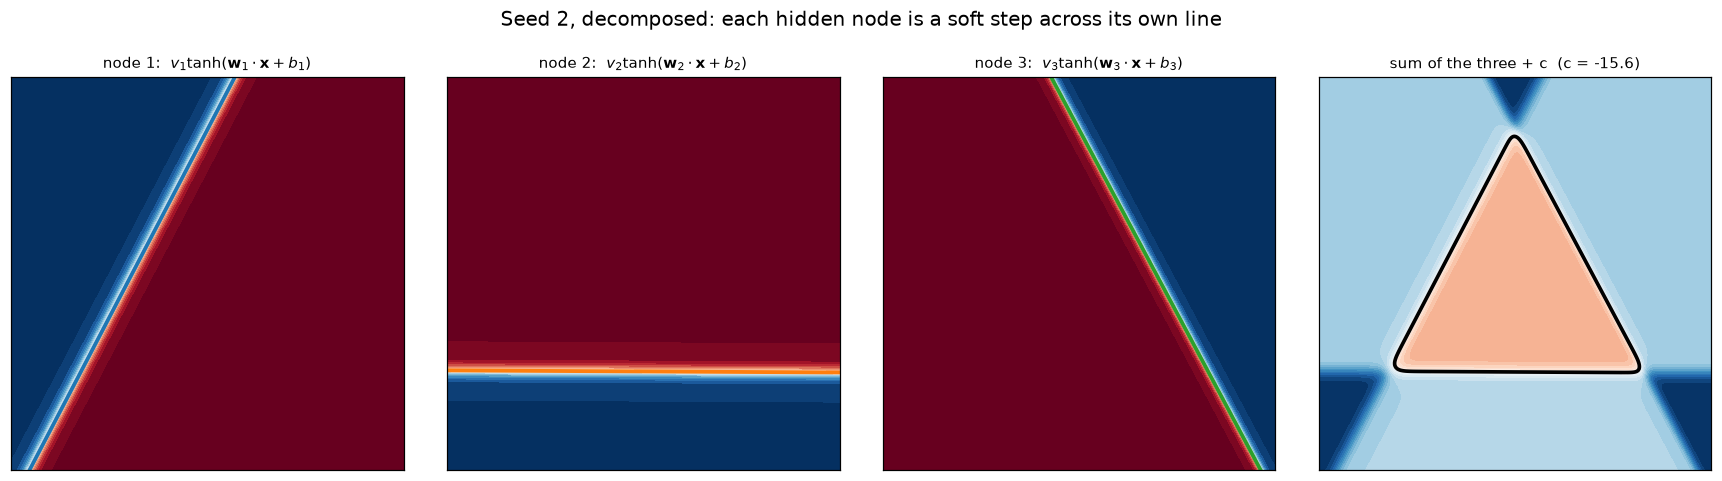

In [5]:
P = tri_nets[2]
W, b, v = canonical_nodes(P)
c = P[1][1][1] - P[1][1][0]
parts = [v[j] * np.tanh(GRID @ W[j] + b[j]) for j in range(3)]
total = sum(parts) + c

fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
vmax = max(np.abs(p).max() for p in parts)
for j, (ax, p) in enumerate(zip(axes, parts)):
    ax.contourf(GX, GY, p.reshape(GX.shape), levels=21, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    draw_line(ax, W[j], b[j], color=NODE_COLORS[j], lw=2.5)
    ax.set_title(fr"node {j+1}:  $v_{j+1}\tanh(\mathbf{{w}}_{j+1}\cdot\mathbf{{x}}+b_{j+1})$", fontsize=10)
tm = np.abs(total).max()
axes[3].contourf(GX, GY, total.reshape(GX.shape), levels=21, cmap="RdBu_r", vmin=-tm, vmax=tm)
axes[3].contour(GX, GY, total.reshape(GX.shape), levels=[0], colors="k", linewidths=2.4)
axes[3].set_title(f"sum of the three + c  (c = {c:.1f})", fontsize=10)
for ax in axes:
    ax.set_xlim(LO, HI); ax.set_ylim(LO, HI); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Seed 2, decomposed: each hidden node is a soft step across its own line",
             fontsize=13, y=1.03)
plt.tight_layout(); plt.show()

Each node votes "+" (red) on the inner side of one edge and "−" outside it. Only where **all three** are red does the sum overcome the negative constant $c$. That's how an AND of half-planes appears in the weights.

## 1C. A disk with 6 hidden nodes

A circle has no straight sides. Do the nodes form a hexagon around it?

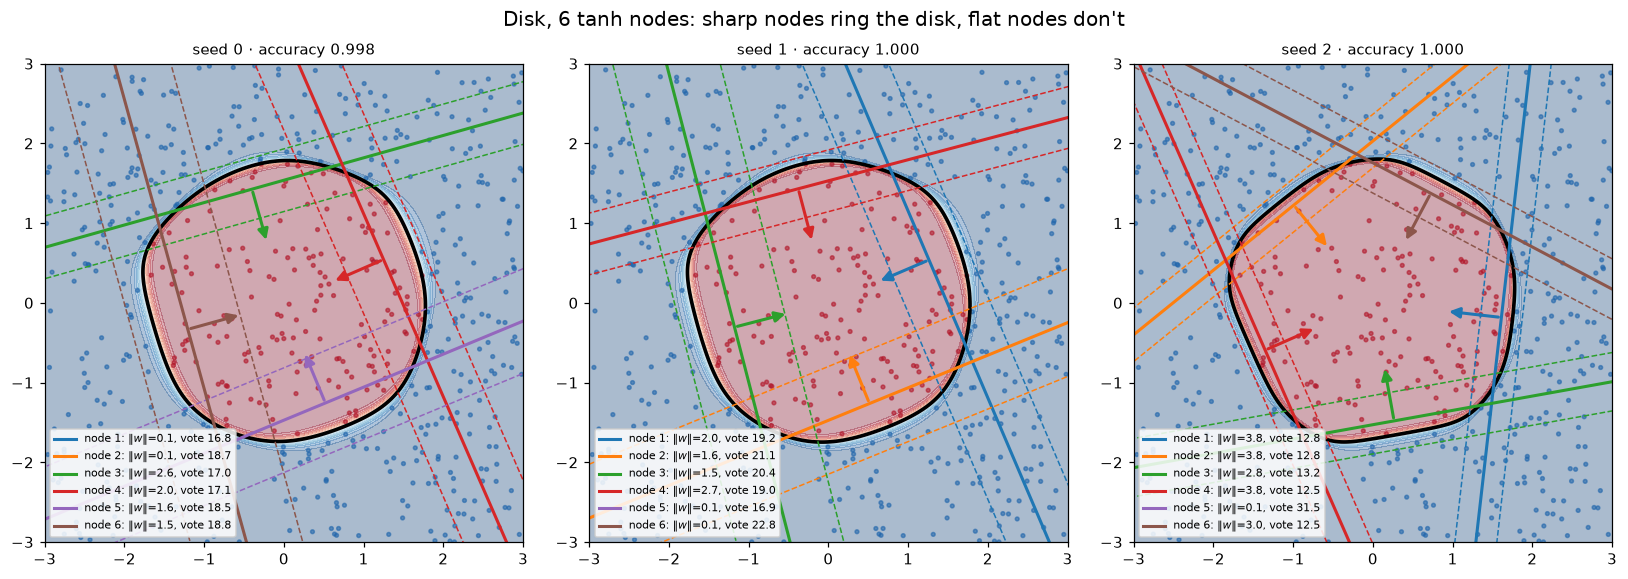

In [6]:
DISK_SEEDS = [0, 1, 2]
disk_nets = {s: train(init_params([2, 6, 2], "tanh", s), X2, y_disk, "tanh", steps=3000, lr=0.02)
             for s in DISK_SEEDS}

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, s in zip(axes, DISK_SEEDS):
    plot_nodes(ax, disk_nets[s], X2, y_disk,
               f"seed {s} · accuracy {accuracy(disk_nets[s], X2, y_disk, 'tanh'):.3f}")
fig.suptitle("Disk, 6 tanh nodes: sharp nodes ring the disk, flat nodes don't", fontsize=13, y=1.0)
plt.tight_layout(); plt.show()

**What to read here.** All three fit the disk almost perfectly, but they use their nodes differently:

- In **seed 2**, every node is moderately sharp ($\lVert\mathbf{w}\rVert \approx 3$–$4$), and the six lines roughly **ring the disk like a hexagon**. The bands are wide enough to overlap, which rounds off the corners into a circle.
- In **seeds 0 and 1**, several nodes have very short weight vectors ($\lVert\mathbf{w}\rVert \approx 0.1$): they are nearly flat ramps, and their lines cross the disk or sit far away. The round boundary is the **level curve of a smooth sum**, and no single node owns any piece of it.

**Answer to question 1.** A first-layer weight row always defines a direction and a line in input space. Those lines become **pieces of the decision boundary** when the nodes are sharp (long $\mathbf{w}_j$, thin bands) — exactly so for the triangle, roughly so for the disk in seed 2. Nodes with short $\mathbf{w}_j$ are smooth **ramps** that get blended, and their lines say little about the boundary. Same data and accuracy, different seeds, different readings: the weights *can* represent the boundary, but nothing forces them to.

# Part 2 — Hidden nodes as templates (image input)

## The images

To check whether weights recover "basic shapes", I need data whose basic shapes I know. So every image is drawn on a $12 \times 12$ canvas from **8 stroke primitives**: four edge bars, a middle horizontal and vertical bar, and two diagonals. A class is a combination of strokes. Each sample is shifted by up to $\pm1$ pixel, given a random brightness in $[0.7, 1]$, and has Gaussian pixel noise ($\sigma = 0.25$) added. Each $12\times12$ image is flattened into a 144-dimensional input vector.

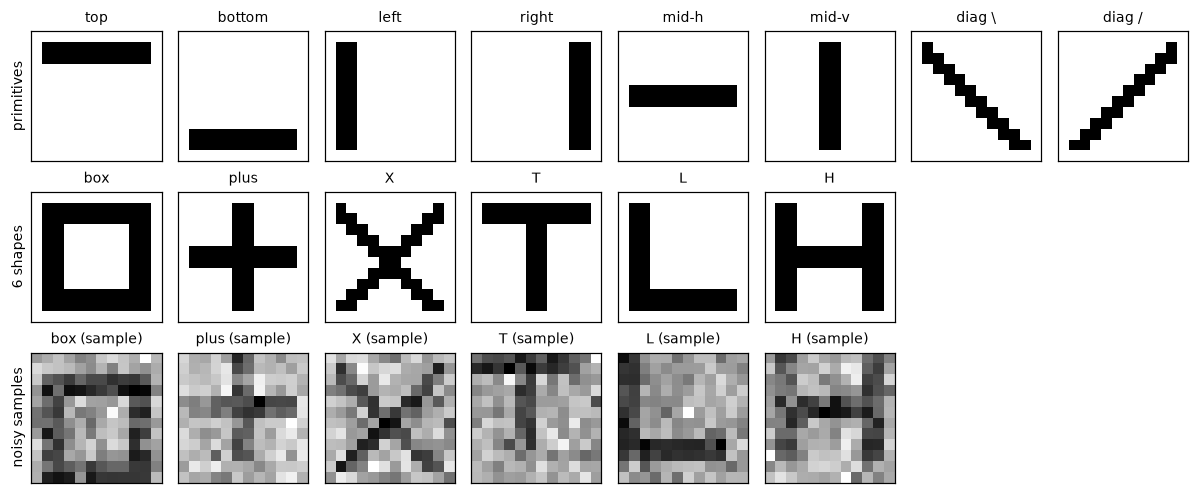

In [7]:
S = 12

def make_primitives():
    P = {}
    def canvas(): return np.zeros((S, S))
    a = canvas(); a[1:3, 1:11] = 1; P["top"] = a
    a = canvas(); a[9:11, 1:11] = 1; P["bottom"] = a
    a = canvas(); a[1:11, 1:3] = 1; P["left"] = a
    a = canvas(); a[1:11, 9:11] = 1; P["right"] = a
    a = canvas(); a[5:7, 1:11] = 1; P["mid-h"] = a
    a = canvas(); a[1:11, 5:7] = 1; P["mid-v"] = a
    a = canvas()
    for i in range(1, 11):
        a[i, max(i - 1, 1):min(i + 1, 11)] = 1
    P["diag \\"] = a
    P["diag /"] = a[:, ::-1].copy()
    return P

PRIM = make_primitives()
PNAMES = list(PRIM)
SHAPES = {"box": ["top", "bottom", "left", "right"], "plus": ["mid-h", "mid-v"],
          "X": ["diag \\", "diag /"], "T": ["top", "mid-v"], "L": ["left", "bottom"],
          "H": ["left", "right", "mid-h"]}

def render(strokes):
    return np.clip(sum(PRIM[p] for p in strokes), 0, 1)

def make_dataset(classes, n_per, shift=1, noise=0.25, seed=0):
    """classes: list of stroke lists. Returns X (n, 144) and labels y."""
    rng = np.random.default_rng(seed)
    X, y = [], []
    for c, strokes in enumerate(classes):
        base = render(strokes)
        for _ in range(n_per):
            img = np.roll(base, tuple(rng.integers(-shift, shift + 1, size=2)), axis=(0, 1))
            img = img * rng.uniform(0.7, 1.0) + noise * rng.standard_normal((S, S))
            X.append(img.ravel()); y.append(c)
    return np.array(X), np.array(y)

def show_img(ax, w, signed=True, title=None):
    """Signed weights: red = positive, blue = negative, white = 0 (each image scaled to its own max)."""
    img = w.reshape(S, S)
    if signed:
        vmax = np.abs(img).max()
        ax.imshow(img, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    else:
        ax.imshow(img, cmap="gray_r")
    ax.set_xticks([]); ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=9)

shape_names = list(SHAPES)
X6, y6 = make_dataset([SHAPES[k] for k in shape_names], 200, seed=0)
X6t, y6t = make_dataset([SHAPES[k] for k in shape_names], 100, seed=1)

fig, axes = plt.subplots(3, 8, figsize=(11, 4.6))
for j, name in enumerate(PNAMES):
    show_img(axes[0, j], PRIM[name].ravel(), signed=False, title=name)
for c, name in enumerate(shape_names):
    show_img(axes[1, c], render(SHAPES[name]).ravel(), signed=False, title=name)
    show_img(axes[2, c], X6[y6 == c][0], signed=False, title=f"{name} (sample)")
for ax in list(axes[1, 6:]) + list(axes[2, 6:]):
    ax.axis("off")
axes[0, 0].set_ylabel("primitives", fontsize=9)
axes[1, 0].set_ylabel("6 shapes", fontsize=9)
axes[2, 0].set_ylabel("noisy samples", fontsize=9)
plt.tight_layout(); plt.show()

**Held fixed in Part 2:** 200 training images per class (100 test images per class, drawn separately), weight decay $\lambda = 0.01$, learning rate 0.01, 2000 steps, ReLU hidden nodes (a ReLU node "fires" when $\mathbf{w}_j\cdot\mathbf{x} + b_j > 0$, which fits the template reading).

## 2A. No hidden layer: one template per class

With no hidden layer, the network is $144 \to 6$ softmax (multinomial logistic regression). Each class $k$ gets one weight row $\mathbf{w}_k$ and score $\mathbf{w}_k \cdot \mathbf{x} + b_k$, so each row is that class's **template**. Here I compare the templates with the **average image** of each class.

test accuracy (no hidden layer): 1.000


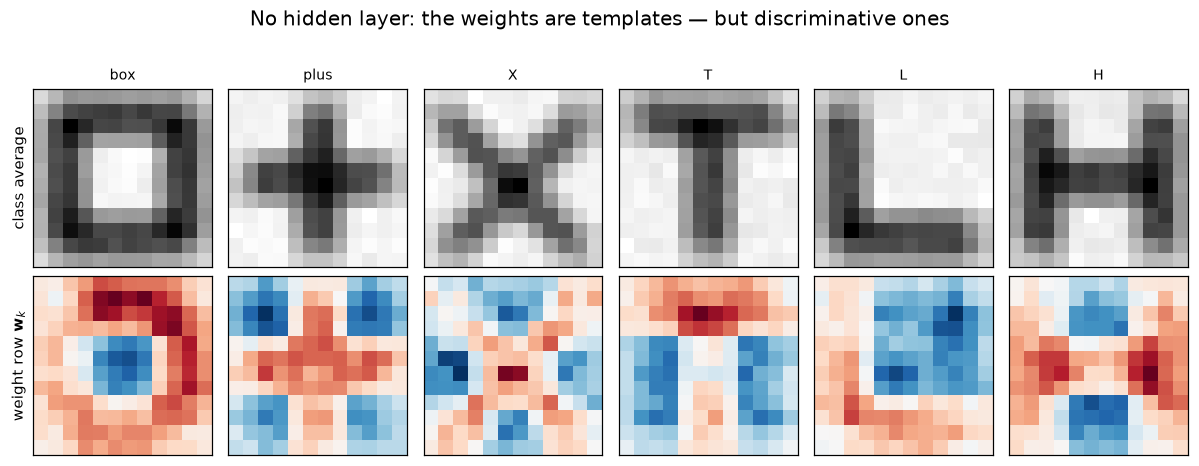

In [8]:
lin = train(init_params([144, 6], "relu", 0), X6, y6, "relu", wd=0.01)
print(f"test accuracy (no hidden layer): {accuracy(lin, X6t, y6t, 'relu'):.3f}")

fig, axes = plt.subplots(2, 6, figsize=(11, 4.2))
for c, name in enumerate(shape_names):
    show_img(axes[0, c], X6[y6 == c].mean(0), signed=False, title=name)
    show_img(axes[1, c], lin[0][0][c])
axes[0, 0].set_ylabel("class average", fontsize=10)
axes[1, 0].set_ylabel("weight row $\\mathbf{w}_k$", fontsize=10)
fig.suptitle("No hidden layer: the weights are templates — but discriminative ones", fontsize=13, y=1.02)
plt.tight_layout(); plt.show()

**What to read here.** The weight rows *resemble* the shapes, but they're not the average images. They are **contrast templates**: red where this class has ink, and **blue where the classes it's most easily confused with have ink but it doesn't**.

- "H" is blue along the top and bottom edges. Those are exactly the strokes that turn an H into a box.
- "box" is blue in the middle, where H, plus, and X have ink.
- Strokes that every competing class also shares get little weight, because they don't help tell classes apart.

So a linear layer's weights describe **what distinguishes** the classes, not what each class looks like.

## 2B. One hidden layer: do the hidden nodes learn strokes?

Now $144 \to 8 \to 6$. Each of the 8 hidden nodes has its own template $\mathbf{w}_j$, and the output layer combines their responses. Below are the hidden templates for two random starts, which test images make each node (seed 0) fire most, and the output weights $v_{k,j}$ that turn node responses into class votes.

seed 0: test accuracy 1.000
seed 1: test accuracy 1.000


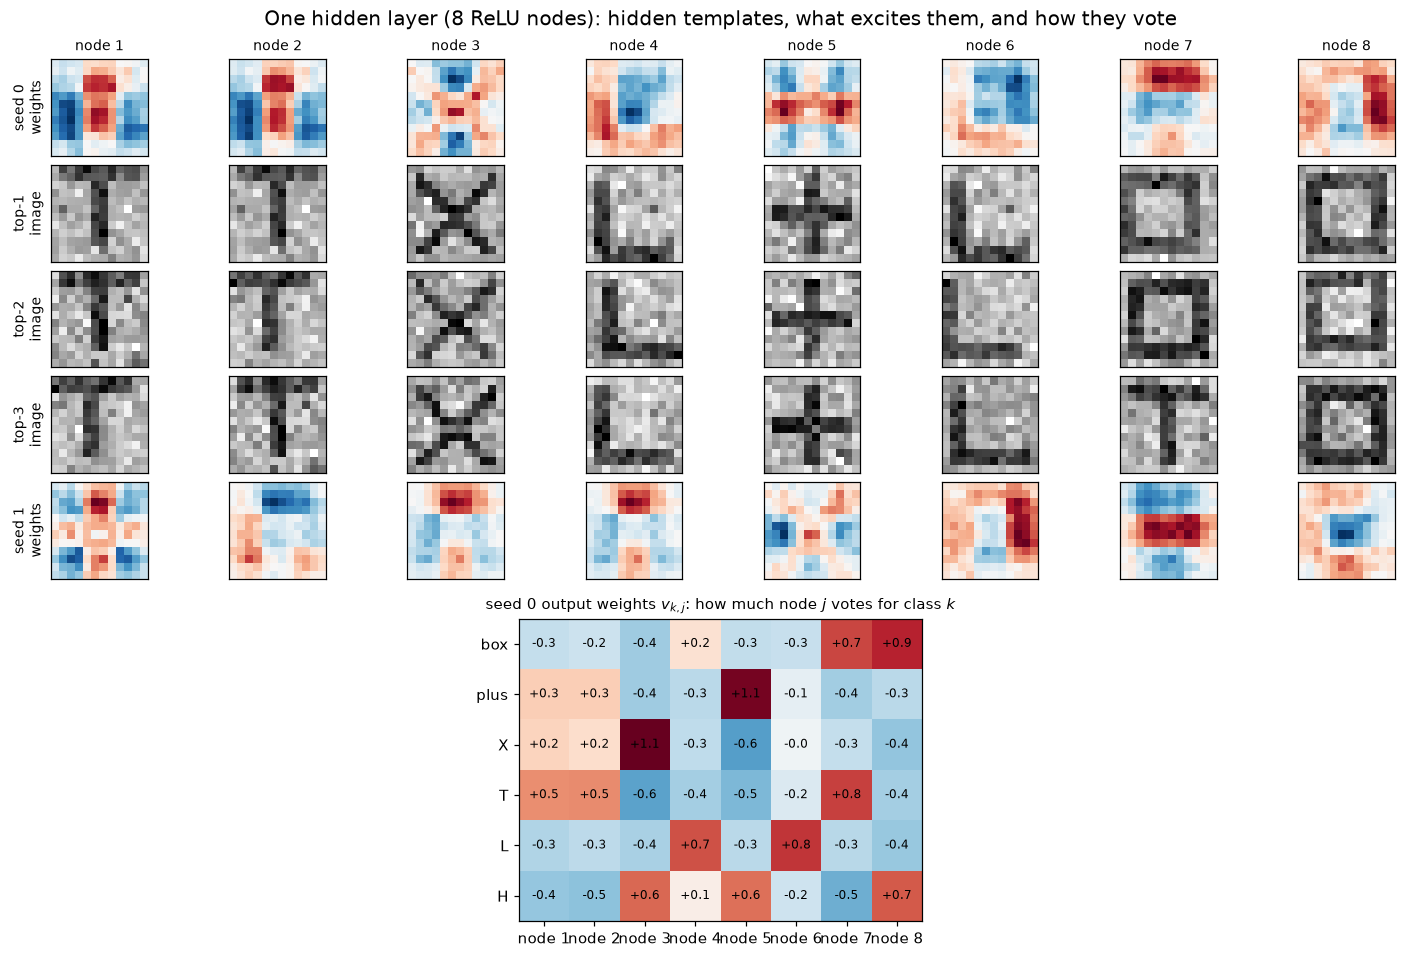

In [9]:
hid = {s: train(init_params([144, 8, 6], "relu", s), X6, y6, "relu", wd=0.01) for s in (0, 1)}
for s, p in hid.items():
    print(f"seed {s}: test accuracy {accuracy(p, X6t, y6t, 'relu'):.3f}")

P = hid[0]
_, cache = forward(P, X6t, "relu")
H_act = cache[1][1]                                      # hidden-node outputs on the test images

fig = plt.figure(figsize=(13, 8.6), layout="constrained")
top, bottom = fig.subfigures(2, 1, height_ratios=[5.2, 3.4])
axes = top.subplots(5, 8)
for j in range(8):
    show_img(axes[0, j], P[0][0][j], title=f"node {j+1}")
    for r, idx in enumerate(np.argsort(-H_act[:, j])[:3]):
        show_img(axes[r + 1, j], X6t[idx], signed=False)
    show_img(axes[4, j], hid[1][0][0][j])
axes[0, 0].set_ylabel("seed 0\nweights", fontsize=9)
for r in range(3):
    axes[r + 1, 0].set_ylabel(f"top-{r+1}\nimage", fontsize=9)
axes[4, 0].set_ylabel("seed 1\nweights", fontsize=9)

ax = bottom.subplots()
V = P[1][0]
vm = np.abs(V).max()
ax.imshow(V, cmap="RdBu_r", vmin=-vm, vmax=vm)
ax.set_xticks(range(8), [f"node {j+1}" for j in range(8)])
ax.set_yticks(range(6), shape_names)
for k in range(6):
    for j in range(8):
        ax.text(j, k, f"{V[k, j]:+.1f}", ha="center", va="center", fontsize=8)
ax.set_title("seed 0 output weights $v_{k,j}$: how much node $j$ votes for class $k$", fontsize=10)
fig.suptitle("One hidden layer (8 ReLU nodes): hidden templates, what excites them, and how they vote",
             fontsize=13)
plt.show()

**What to read here.**

- **Many hidden nodes are whole-shape detectors, not strokes.** In seed 0, node 3's top images are all X's, node 5's are plus signs, and node 8's are boxes. Each looks like a contrast template for one class, as in 2A. With only 6 easy classes, "one detector per class" is the simplest solution, so there's no pressure to share stroke features.
- **Some nodes are redundant.** Nodes 1 and 2 are near-duplicates that both fire for T. With 8 nodes for 6 classes, the spare capacity simply gets copied.
- **The output table reads like a lookup.** Each class gets a strong positive vote from its own detector node(s) and mild negative votes from the others.
- **The two seeds learn different templates** with the same accuracy. Hidden nodes aren't uniquely defined: their order is arbitrary, and many different sets of features solve the task equally well.

So "basic shapes" didn't appear. The nodes learned the *classes* directly, because that was enough. The next experiment gives the network a reason to learn strokes.

## 2C. A task that rewards strokes — and a constraint that changes the answer

Maybe 6 classes are simply too easy to need strokes. So I design a task where stroke detectors are the *natural* solution:

- **28 classes**, one for every **pair** of the 8 primitives,
- a hidden layer of exactly **8 nodes**, one per primitive if the network wants that.

To measure "looks like a stroke", I compute the **correlation** between each hidden template and each primitive image (both centered), and record each node's best match (1 = identical pattern, 0 = unrelated).

Then I change **one** thing: force the first-layer weights to be **non-negative** (`nonneg=True`). A node can then only *add up* ink in some pixels; it can't use negative weights to penalize ink elsewhere. This constraint is known to favor **parts-based** features — the classic example is non-negative matrix factorization (Lee & Seung, 1999).

In [10]:
PAIRS = list(combinations(PNAMES, 2))
Xp, yp = make_dataset([list(p) for p in PAIRS], 60, seed=0)
Xpt, ypt = make_dataset([list(p) for p in PAIRS], 30, seed=1)

PM = np.array([PRIM[p].ravel() for p in PNAMES])
PM = PM - PM.mean(1, keepdims=True)
PM /= np.linalg.norm(PM, axis=1, keepdims=True)

def stroke_match(W):
    """Correlation of each (centered) weight row with each (centered) primitive: shape (nodes, 8)."""
    Wc = W - W.mean(1, keepdims=True)
    return (Wc / np.linalg.norm(Wc, axis=1, keepdims=True)) @ PM.T

pair_nets, summary = {}, []
for mode in ("free", "non-negative"):
    for s in range(3):
        p = train(init_params([144, 8, 28], "relu", s), Xp, yp, "relu", wd=0.01,
                  nonneg=(mode == "non-negative"))
        pair_nets[(mode, s)] = p
        M = stroke_match(p[0][0])
        summary.append((mode, s, accuracy(p, Xpt, ypt, "relu"), M.max(1).mean(), len(set(M.argmax(1)))))
print(f"{'weights':13s} {'seed':>4s} {'test acc':>9s} {'best stroke corr (mean)':>24s} {'distinct strokes':>17s}")
for mode, s, acc, bc, nd in summary:
    print(f"{mode:13s} {s:4d} {acc:9.3f} {bc:24.2f} {nd:17d}")

weights       seed  test acc  best stroke corr (mean)  distinct strokes
free             0     0.996                     0.46                 6
free             1     0.996                     0.46                 7
free             2     0.996                     0.49                 6
non-negative     0     0.999                     0.48                 6
non-negative     1     0.998                     0.48                 5
non-negative     2     0.999                     0.48                 6


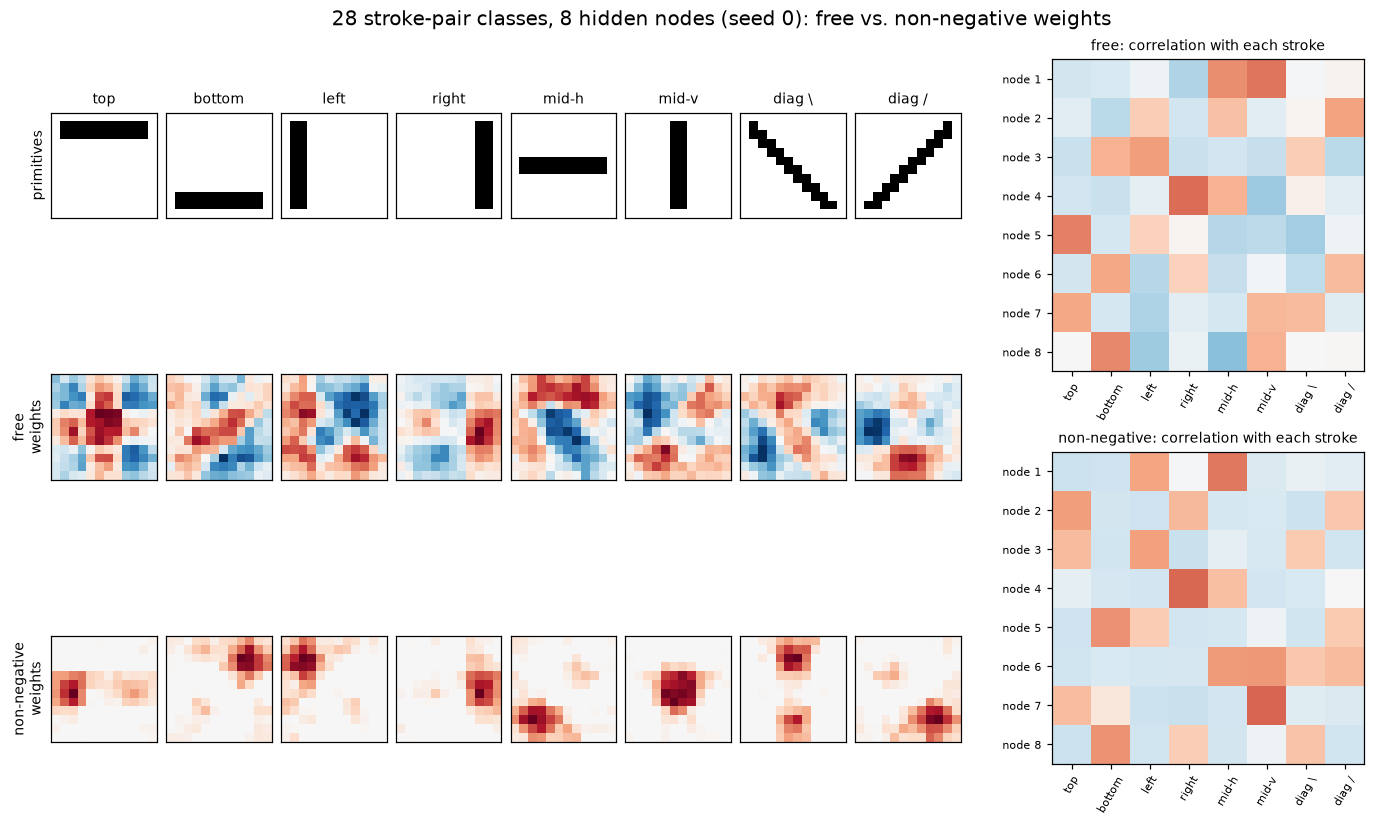

In [11]:
fig = plt.figure(figsize=(13, 7.4), layout="constrained")
sub = fig.subfigures(1, 2, width_ratios=[2.1, 1])
axes = sub[0].subplots(3, 8)
for j, name in enumerate(PNAMES):
    show_img(axes[0, j], PRIM[name].ravel(), signed=False, title=name)
for r, mode in enumerate(("free", "non-negative")):
    W = pair_nets[(mode, 0)][0][0]
    for j in range(8):
        show_img(axes[r + 1, j], W[j])
    axes[r + 1, 0].set_ylabel(f"{mode}\nweights", fontsize=9)
axes[0, 0].set_ylabel("primitives", fontsize=9)

axm = sub[1].subplots(2, 1)
for ax, mode in zip(axm, ("free", "non-negative")):
    M = stroke_match(pair_nets[(mode, 0)][0][0])
    ax.imshow(M, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(8), PNAMES, rotation=60, fontsize=7)
    ax.set_yticks(range(8), [f"node {j+1}" for j in range(8)], fontsize=7)
    ax.set_title(f"{mode}: correlation with each stroke", fontsize=9)
fig.suptitle("28 stroke-pair classes, 8 hidden nodes (seed 0): free vs. non-negative weights", fontsize=13)
plt.show()

**What to read here.**

- **Free weights still don't become strokes.** Even though one-node-per-stroke would work perfectly, each node's best stroke correlation is only around 0.5. The nodes remain **mixtures** with positive and negative parts. Nothing in the training objective prefers "one node = one stroke" over any other combination that carries the same information.
- **Non-negative weights look completely different.** The templates become **compact, localized spots**: "is there ink at this corner / edge midpoint / center?" They're far easier to interpret, but they're **still not the strokes** — the table shows the same stroke correlation (about 0.5) as the free weights. A few well-placed spots are enough to tell which pair of strokes is present (each stroke covers different spots), and weight decay favors small, compact weights. The network learns the **cheapest sufficient evidence**, not the parts the images were generated from.

**Answer to question 2.** Hidden weights are templates, but templates for whatever **helps the task**, shaped by the constraints you impose. They match human "basic shapes" only when the task, architecture, and constraints happen to favor that.

## 2D. Move the shapes around: templates are tied to pixel positions

A fully connected weight is attached to **one pixel position**. What happens to the no-hidden-layer templates of 2A if the shapes are shifted by up to $\pm3$ pixels instead of $\pm1$?

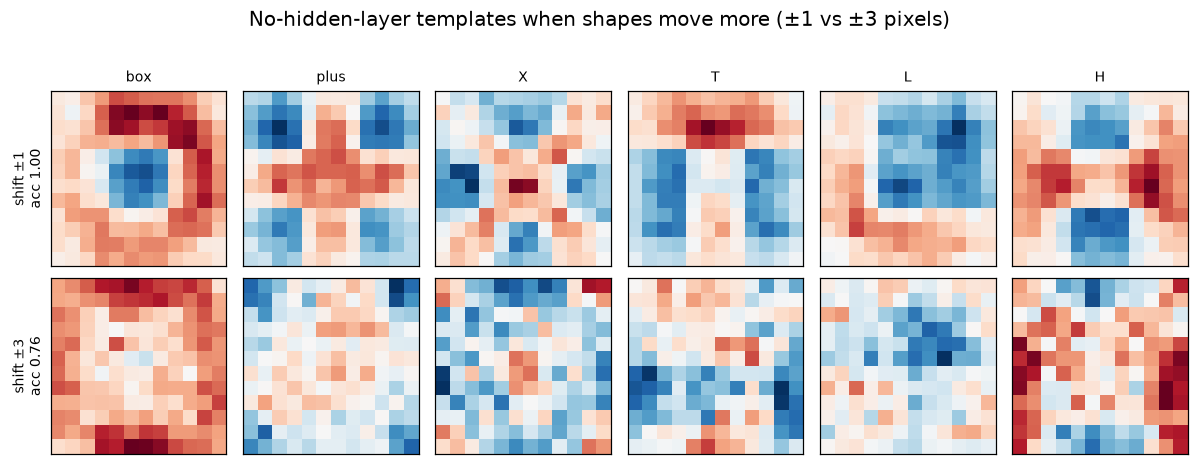

In [12]:
fig, axes = plt.subplots(2, 6, figsize=(11, 4.2))
for r, shift in enumerate((1, 3)):
    Xs, ys = make_dataset([SHAPES[k] for k in shape_names], 200, shift=shift, seed=0)
    Xst, yst = make_dataset([SHAPES[k] for k in shape_names], 100, shift=shift, seed=1)
    p = train(init_params([144, 6], "relu", 0), Xs, ys, "relu", wd=0.01)
    for c, name in enumerate(shape_names):
        show_img(axes[r, c], p[0][0][c], title=name if r == 0 else None)
    axes[r, 0].set_ylabel(f"shift ±{shift}\nacc {accuracy(p, Xst, yst, 'relu'):.2f}", fontsize=9)
fig.suptitle("No-hidden-layer templates when shapes move more (±1 vs ±3 pixels)", fontsize=13, y=1.02)
plt.tight_layout(); plt.show()

**What to read here.** With more movement, the templates **smear out and get noisy**, because a single template has to cover the shape in every position it might appear. They lose the crisp strokes, and test accuracy drops from 1.00 to about 0.76. That's the limit of the template reading for a fully connected layer: it learns *one picture per pixel position*. **Convolutional networks** fix this by sliding one small set of weights over the image, so the same stroke detector is reused everywhere. Their first-layer filters typically end up looking like edges and strokes — the "basic shapes" this question is really about.

## Recap — what a weight matrix means

| Where | What one row $\mathbf{w}_j$ means | When it's easy to read | When it isn't |
|---|---|---|---|
| First layer, low-dim input | a line/hyperplane $\mathbf{w}_j\cdot\mathbf{x}+b_j=0$; $\mathbf{w}_j$ points to the "on" side; $\lVert\mathbf{w}_j\rVert$ sets sharpness | sharp nodes (long $\mathbf{w}_j$) → the lines are boundary pieces (triangle; disk seed 2) | short $\mathbf{w}_j$ → nearly linear ramps that get blended; their lines mean little |
| First layer, image input | a template: the node responds most to inputs that look like $\mathbf{w}_j$ | no hidden layer → one **contrast template** per class | hidden layer → whatever suffices: whole-class detectors (easy task) or mixtures (harder task), different for each seed; tied to pixel positions |
| Output layer | votes: how much each hidden node counts for or against each class | always readable as a table | its meaning depends on what the hidden nodes detect |

**Things I want to remember**

- Weights are **discriminative**: they encode what *separates* the classes, not a picture of each class.
- Hidden nodes are **not unique**: they can be reordered, sign-flipped (tanh), or mixed, with no change in what the network computes. Interpret the *layer*, not one node in isolation.
- Networks learn the **simplest sufficient features**: class detectors when classes are easy (2B), spot detectors under non-negativity (2C) — not necessarily the parts the data was made from.
- Readable features come from **structure and constraints**, not by default: few sharp nodes (Part 1), non-negativity (2C), and in practice convolution (2D).
- Layers deeper than the first can't be drawn as input images directly, because they combine features of features. Understanding them needs other tools (for example, finding inputs that maximize a node's response).

## Acknowledgment

This study accompanies my notes for **24-887 — Machine Learning & Artificial Intelligence for Engineers**, taught by Professor Levent Burak Kara as part of Carnegie Mellon University's [AI Engineering Fundamentals](https://www.cmu.edu/online/ai-engineering-fundamentals) graduate certificate. Credit for the course material goes to the instructor and CMU; the experiments and any errors here are my own.